In [2]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path
import sys
import numpy as np
sys.path.append("../model/ml-mobileone")

### Dataset

In [3]:
label_class_index = {
    "dilmah": 0, "g7": 1, "jack-jill": 2, "karo": 3, "nestea_atiso": 4, 
    "nestea_chanh": 5, "nestea_hoaqua": 6, "orion": 7, "tipo": 8, "y40": 9
}

folder_dir = Path("/home/filelele/personal_project/belt-conveyor-object-count/dataset/deduplicated_cropped_frames/")
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tiff"}

image_paths = []
labels = []

for p in folder_dir.rglob("*"):
    if p.suffix.lower() in IMG_EXTENSIONS:
        class_name = p.parent.name
        if class_name in label_class_index:
            image_paths.append(str(p))
            labels.append(label_class_index[class_name])

print(f"Total images: {len(image_paths)}, Total labels: {len(labels)}")



Total images: 1674, Total labels: 1674


In [4]:
from collections import Counter
# Reverse mapping: index -> class name
idx_to_class = {v: k for k, v in label_class_index.items()}
counts = Counter(labels)
counts_list = []
for i in range(len(counts)):
    counts_list.append(counts[i])
print("\n--- Samples per Class ---")
for idx in sorted(idx_to_class.keys()):
    class_name = idx_to_class[idx]
    num_samples = counts.get(idx, 0)
    print(f"{class_name:<15} (id: {idx}): {num_samples} samples")


--- Samples per Class ---
dilmah          (id: 0): 252 samples
g7              (id: 1): 394 samples
jack-jill       (id: 2): 51 samples
karo            (id: 3): 114 samples
nestea_atiso    (id: 4): 161 samples
nestea_chanh    (id: 5): 164 samples
nestea_hoaqua   (id: 6): 178 samples
orion           (id: 7): 192 samples
tipo            (id: 8): 88 samples
y40             (id: 9): 80 samples


In [5]:
class CustomDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        """
        Store paths, annotations, and transforms.
        Avoid loading all images into memory here!
        """
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        """Returns the total number of samples."""
        return len(self.image_paths)

    def __getitem__(self, index):
        """Loads and returns a single sample (features, target) by index."""
        # 1. Load data
        img_path = self.image_paths[index]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[index]

        # 2. Apply transformations/augmentations
        if self.transform:
            image = self.transform(image)

        # 3. Convert target to tensor if not already
        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [6]:
from torch.utils.data import DataLoader
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomAffine(
        degrees=360,
        translate=(0.1,0.1),
        scale=(0.9,1.1),
        shear=5
    ),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.GaussianBlur(kernel_size=(5,5), sigma=(0.1,1.8)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225]), #ImageNet mean std
])

val_test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])
train_base_dataset = CustomDataset(image_paths, labels, transform=train_transform)
eval_base_dataset  = CustomDataset(image_paths, labels, transform=val_test_transform)

In [7]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

all_indices = np.arange(len(labels))

# Stratify guarantees class proportions are preserved
train_val_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

# Test set uses eval transforms
test_dataset = Subset(eval_base_dataset, test_idx)
print(f"Total: {len(labels)} | Train+Val pool: {len(train_val_idx)} | Test: {len(test_dataset)}")


Total: 1674 | Train+Val pool: 1255 | Test: 419


### Model

In [8]:
from mobileone import mobileone, reparameterize_model
import torch.nn as nn
pretrained_model=mobileone(variant='s4')
checkpoint_s4 = torch.load('../model/checkpoints/mobileone_s4_unfused.pth.tar')
pretrained_model.load_state_dict(checkpoint_s4)


/tmp/ipykernel_1022977/2939807056.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_s4 = torch.load('../model/checkpoints/mobileone_s4_unfused.pth.tar')


<All keys matched successfully>

In [9]:
pretrained_model.type

<bound method Module.type of MobileOne(
  (stage0): MobileOneBlock(
    (se): Identity()
    (activation): ReLU()
    (rbr_conv): ModuleList(
      (0): Sequential(
        (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (rbr_scale): Sequential(
      (conv): Conv2d(3, 64, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (stage1): Sequential(
    (0): MobileOneBlock(
      (se): Identity()
      (activation): ReLU()
      (rbr_conv): ModuleList(
        (0): Sequential(
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=64, bias=False)
          (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (rbr_scale): Sequential(
        (conv): Conv2d

In [10]:
in_features = pretrained_model.linear.in_features
pretrained_model.linear = nn.Linear(in_features, len(label_class_index.keys()))

In [11]:
# 1. Freeze all layers
for param in pretrained_model.parameters():
    param.requires_grad = False
# 2. Unfreeze stage4
for param in pretrained_model.stage4.parameters():
    param.requires_grad = True
# 3. Unfreeze classification head
for param in pretrained_model.linear.parameters():
    param.requires_grad = True
# Sanity check print
trainable = sum(p.numel() for p in pretrained_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in pretrained_model.parameters())

### Verify some hyperpams with k-fold

In [60]:
import copy
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

def train_one_fold(
    model,
    train_dataset,
    val_dataset,
    criterion,
    optimizer,
    train_batch_size: int = 32,
    val_batch_size: int = 64,
    max_epochs: int = 50,
    class_counts: list = None,          # list or tensor of sample count per class
    patience: int = 7,
    min_delta: float = 1e-4,
    scheduler = None,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
    num_workers: int = 4
):
    model = model.to(device)
    
    # --- 1. Prepare DataLoaders ---
    if class_counts is not None:
        # Calculate sample weights for WeightedRandomSampler
        class_weights = 1.0 / torch.tensor(class_counts, dtype=torch.float)
        
        # Expecting train_dataset to have .targets or .labels
        # If Subset from KFold, index into underlying dataset targets
        if hasattr(train_dataset, "targets"):
            targets = train_dataset.targets
        elif hasattr(train_dataset, "dataset") and hasattr(train_dataset.dataset, "targets"):
            targets = [train_dataset.dataset.targets[i] for i in train_dataset.indices]
        else:
            # Fallback: extract labels from dataset
            targets = [train_dataset[i][1] for i in range(len(train_dataset))]
            
        sample_weights = [class_weights[t] for t in targets]
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        train_loader = DataLoader(
            train_dataset,
            batch_size=train_batch_size,
            sampler=sampler,
            num_workers=num_workers,
            pin_memory=True
        )
    else:
        train_loader = DataLoader(
            train_dataset,
            batch_size=train_batch_size,
            shuffle=True,
            num_workers=num_workers,
            pin_memory=True
        )

    val_loader = DataLoader(
        val_dataset,
        batch_size=val_batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True
    )

    # --- 2. Trackers & Early Stopping State ---
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }
    
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0

    # --- 3. Training Loop ---
    for epoch in range(1, max_epochs + 1):
        # TRAIN
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{max_epochs} [Train]", leave=False)
        for images, targets in pbar:
            images, targets = images.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct_train += (preds == targets).sum().item()
            total_train += targets.size(0)

            pbar.set_postfix(batch_loss=f"{loss.item():.4f}")

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # VALIDATION
        model.eval()
        val_running_loss = 0.0
        correct_val = 0
        total_val = 0
        if class_counts is not None:
            val_class_weights = class_weights/class_weights.sum()
            val_criterion = nn.CrossEntropyLoss(weight=val_class_weights.to(device))
        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(device), targets.to(device)
                outputs = model(images)
                loss = val_criterion(outputs, targets)

                val_running_loss += loss.item() * images.size(0)
                preds = outputs.argmax(dim=1)
                correct_val += (preds == targets).sum().item()
                total_val += targets.size(0)

        epoch_val_loss = val_running_loss / total_val
        epoch_val_acc = correct_val / total_val

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(epoch_val_loss)
            else:
                scheduler.step()

        # Log history
        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)

        print(
            f"Epoch {epoch:02d}/{max_epochs:02d} | "
            f"Train Loss: {epoch_train_loss:.4f} - Acc: {epoch_train_acc*100:.2f}% | "
            f"Val Loss: {epoch_val_loss:.4f} - Acc: {epoch_val_acc*100:.2f}%"
        )

        # --- Early Stopping Check ---
        if epoch_val_loss < (best_val_loss - min_delta):
            best_val_loss = epoch_val_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered at epoch {epoch}. Best Val Loss: {best_val_loss:.4f}")
                break

    # Restore best weights
    model.load_state_dict(best_weights)
    return model, history


### Step 1: Do k-fold

In [15]:
from sklearn.model_selection import StratifiedKFold

# Labels for the train_val subset
train_val_labels = [labels[i] for i in train_val_idx]

# Calculate class counts across the train_val pool (for WeightedRandomSampler)
class_counts_dict = Counter(train_val_labels)
num_classes = len(class_counts_dict)
class_counts = [class_counts_dict[c] for c in range(num_classes)]
print("Class counts (Train+Val):", class_counts)

# Setup K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_sub_idx, val_sub_idx) in enumerate(skf.split(train_val_idx, train_val_labels)):
    print(f"\n{'='*20} Fold {fold + 1} / 5 {'='*20}")
    
    # 1. Map sub-indices back to global dataset indices
    fold_train_idx = train_val_idx[train_sub_idx]
    fold_val_idx = train_val_idx[val_sub_idx]
    
    # 2. Slice the subsets using appropriate transforms
    fold_train_dataset = Subset(train_base_dataset, fold_train_idx)
    fold_val_dataset   = Subset(eval_base_dataset, fold_val_idx)
    
    # 3. Re-initialize a fresh model & optimizer for each fold
    fold_model = copy.deepcopy(pretrained_model)
    
    optimizer = torch.optim.AdamW(fold_model.parameters(), lr=1e-4, weight_decay=1e-2)
    criterion = torch.nn.CrossEntropyLoss()
    
    # 4. Train fold
    best_model, history = train_one_fold(
        model=fold_model,
        train_dataset=fold_train_dataset,
        val_dataset=fold_val_dataset,
        criterion=criterion,
        optimizer=optimizer,
        train_batch_size=64,
        val_batch_size=128,
        max_epochs=100,
        class_counts=class_counts,
        patience=7
    )
    
    fold_results.append({
        "fold": fold + 1,
        "best_model": best_model,
        "history": history,
        "final_val_loss": min(history["val_loss"]),
        "final_val_acc": max(history["val_acc"]),
    })


Class counts (Train+Val): [189, 295, 38, 86, 121, 123, 133, 144, 66, 60]

==================== Fold 1 / 5 ====================


Epoch 01/100 | Train Loss: 1.9028 - Acc: 55.68% | Val Loss: 1.4560 - Acc: 82.47%


Epoch 02/100 | Train Loss: 1.0875 - Acc: 93.23% | Val Loss: 0.8024 - Acc: 96.81%


Epoch 03/100 | Train Loss: 0.5468 - Acc: 99.40% | Val Loss: 0.4415 - Acc: 98.41%


Epoch 04/100 | Train Loss: 0.2667 - Acc: 99.60% | Val Loss: 0.2658 - Acc: 98.80%


...

Epoch 69/100 | Train Loss: 0.0009 - Acc: 100.00% | Val Loss: 0.0018 - Acc: 100.00%


Epoch 70/100 | Train Loss: 0.0007 - Acc: 100.00% | Val Loss: 0.0017 - Acc: 100.00%


Epoch 71/100 | Train Loss: 0.0006 - Acc: 100.00% | Val Loss: 0.0019 - Acc: 100.00%


Epoch 72/100 | Train Loss: 0.0006 - Acc: 100.00% | Val Loss: 0.0019 - Acc: 100.00%


Epoch 73/100 | Train Loss: 0.0008 - Acc: 100.00% | Val Loss: 0.0015 - Acc: 100.00%
Early stopping triggered at epoch 73. Best Val Loss: 0.0015


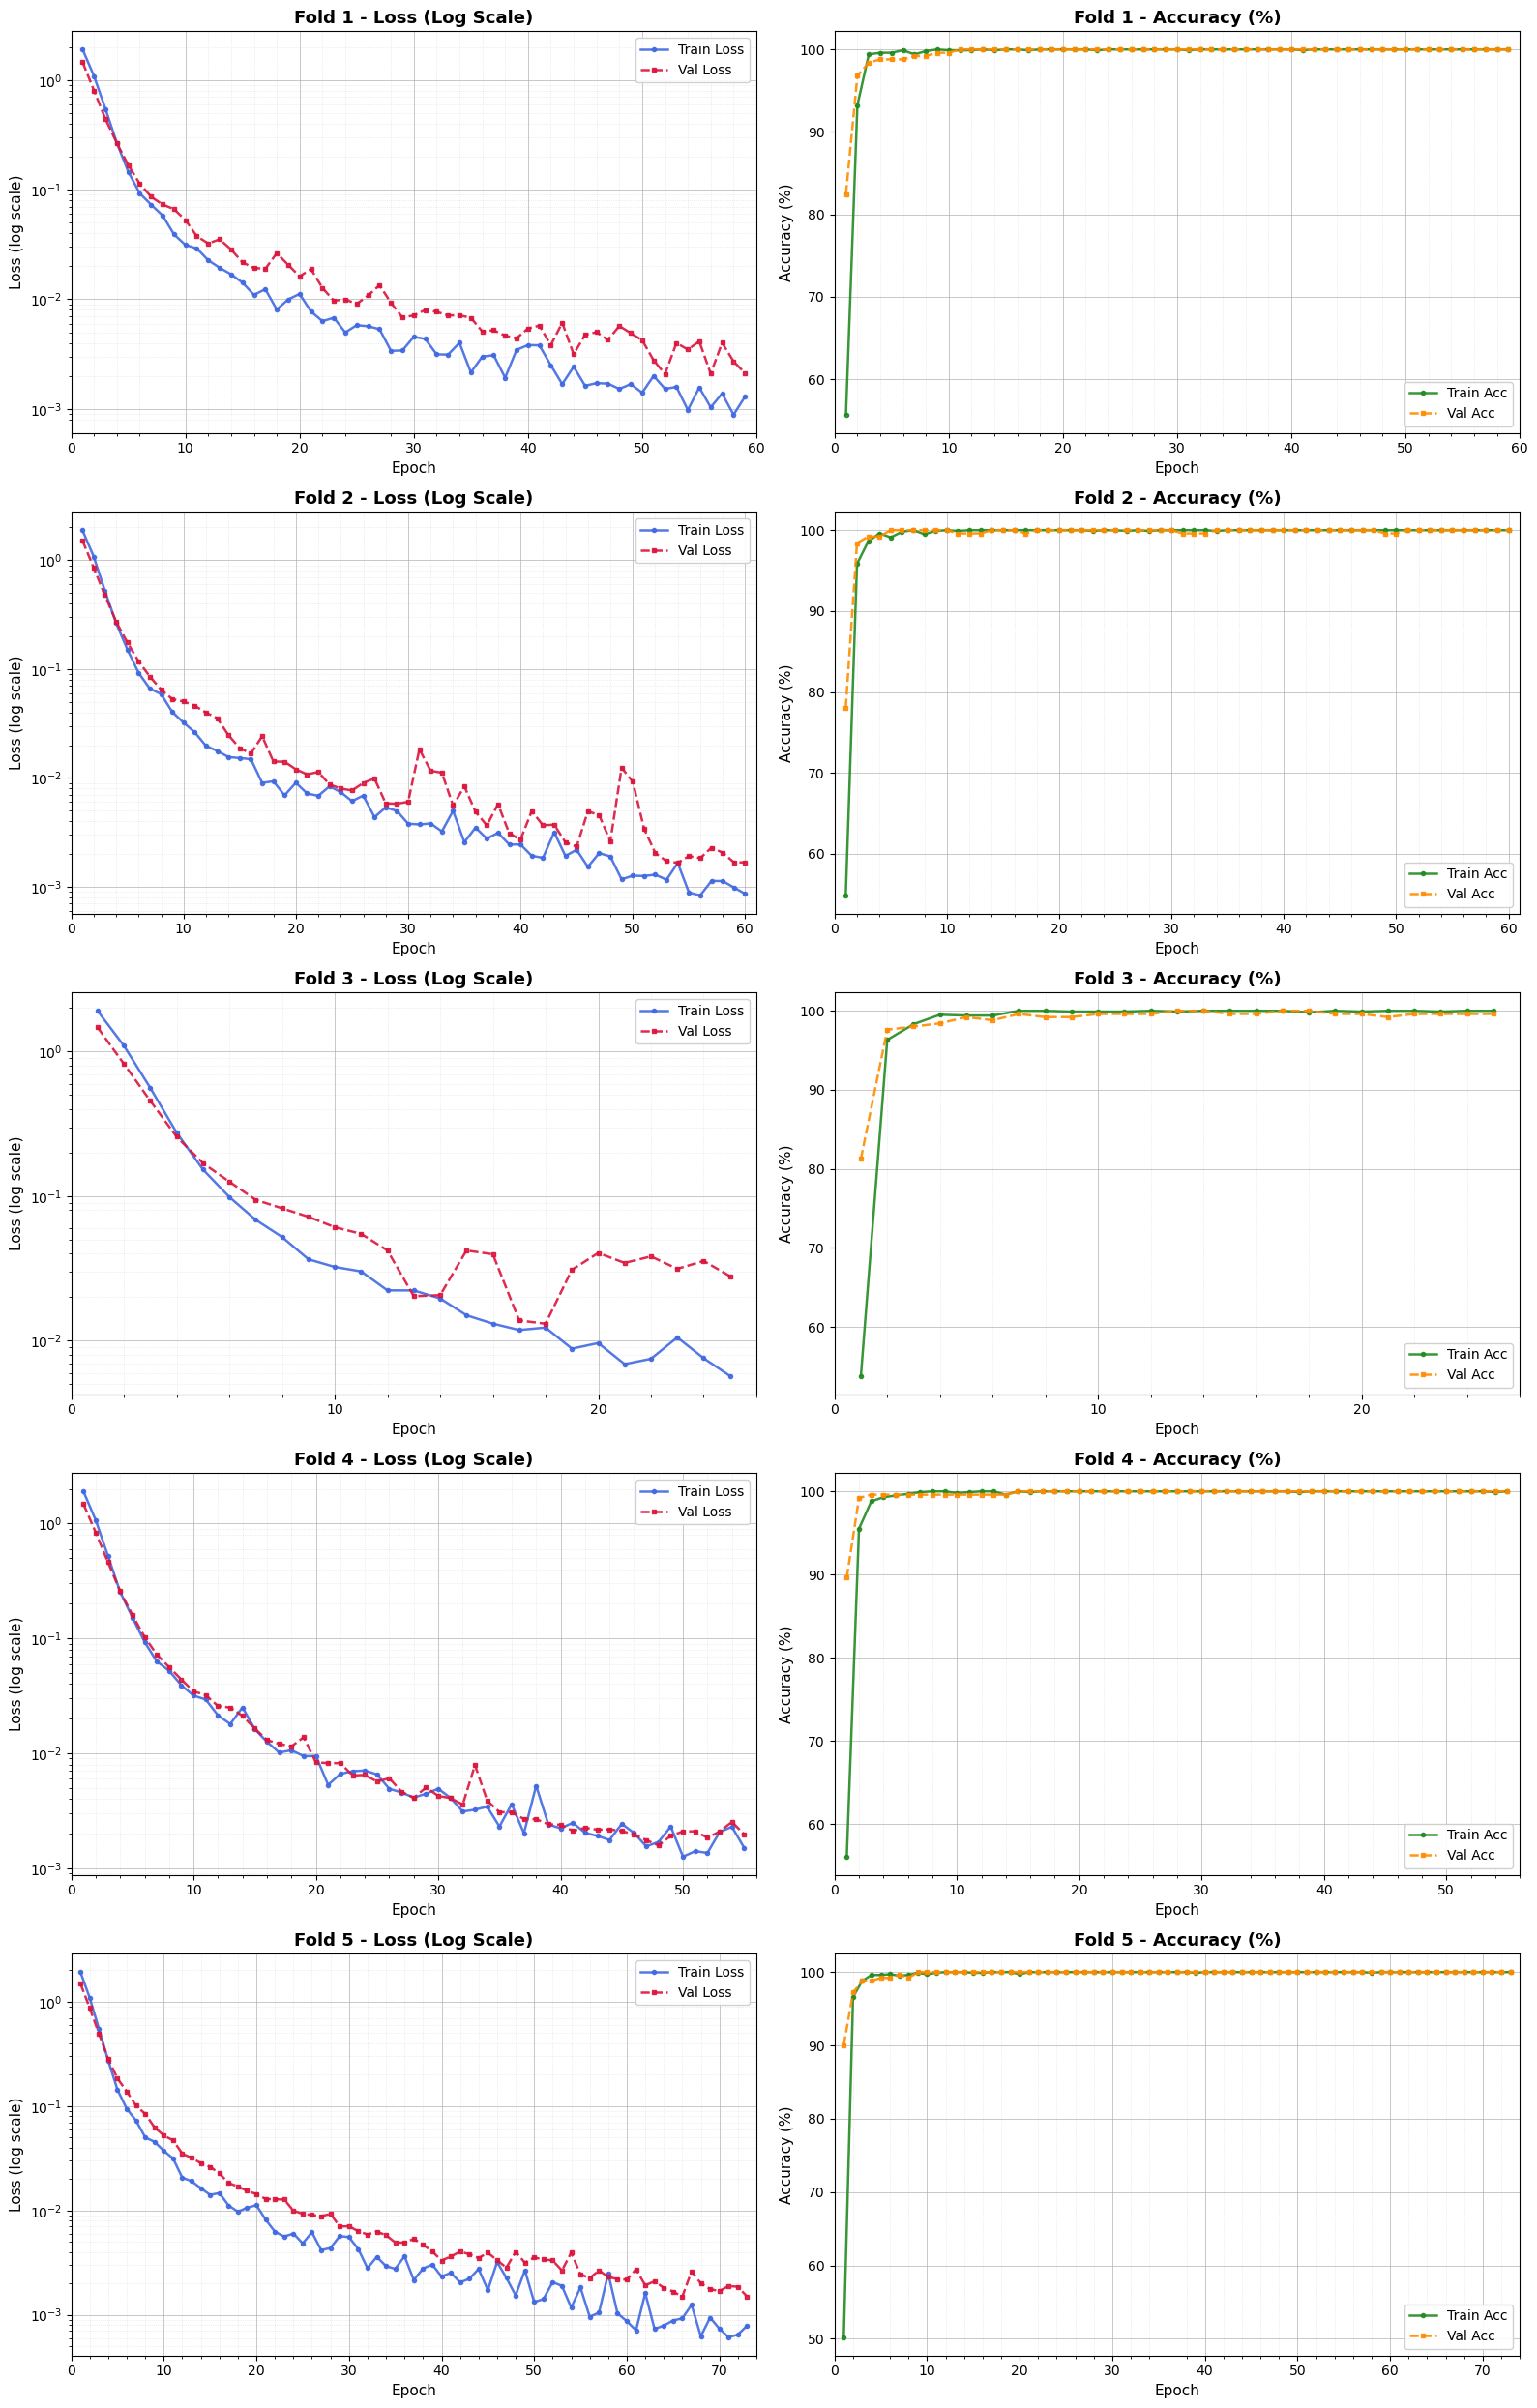

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

num_folds = len(fold_results)
fig, axes = plt.subplots(num_folds, 2, figsize=(16, 5 * num_folds))

# If only 1 fold, wrap axes in 2D array for consistent indexing
if num_folds == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, res in enumerate(fold_results):
    fold = res["fold"]
    hist = res["history"]
    epochs = range(1, len(hist["train_loss"]) + 1)
    
    # ----------------- 1. Loss Curve (Log Scale + Markers) -----------------
    ax_loss = axes[idx, 0]
    ax_loss.plot(
        epochs, hist["train_loss"], 
        label="Train Loss", color="royalblue", lw=1.8, 
        marker="o", markersize=3, alpha=0.9
    )
    ax_loss.plot(
        epochs, hist["val_loss"], 
        label="Val Loss", color="crimson", lw=1.8, linestyle="--", 
        marker="s", markersize=3, alpha=0.9
    )
    ax_loss.set_yscale("log")
    ax_loss.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax_loss.xaxis.set_minor_locator(ticker.MultipleLocator(2))
    ax_loss.set_xlim(0, len(epochs) + 1)
    ax_loss.grid(True, which="major", linestyle="-", linewidth=0.7, alpha=0.7)
    ax_loss.grid(True, which="minor", linestyle=":", linewidth=0.5, alpha=0.4)
    ax_loss.set_title(f"Fold {fold} - Loss (Log Scale)", fontsize=13, fontweight="bold")
    ax_loss.set_xlabel("Epoch", fontsize=11)
    ax_loss.set_ylabel("Loss (log scale)", fontsize=11)
    ax_loss.legend(loc="upper right", framealpha=0.9)
    
    # ----------------- 2. Accuracy Curve (With Markers) -----------------
    ax_acc = axes[idx, 1]
    train_acc = [a * 100 if a <= 1.0 else a for a in hist["train_acc"]]
    val_acc   = [a * 100 if a <= 1.0 else a for a in hist["val_acc"]]
    
    ax_acc.plot(
        epochs, train_acc, 
        label="Train Acc", color="forestgreen", lw=1.8, 
        marker="o", markersize=3, alpha=0.9
    )
    ax_acc.plot(
        epochs, val_acc, 
        label="Val Acc", color="darkorange", lw=1.8, linestyle="--", 
        marker="s", markersize=3, alpha=0.9
    )
    ax_acc.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax_acc.xaxis.set_minor_locator(ticker.MultipleLocator(2))
    ax_acc.set_xlim(0, len(epochs) + 1)
    ax_acc.set_ylim(auto=True)
    ax_acc.grid(True, which="major", linestyle="-", linewidth=0.7, alpha=0.7)
    ax_acc.grid(True, which="minor", linestyle=":", linewidth=0.5, alpha=0.4)
    ax_acc.set_title(f"Fold {fold} - Accuracy (%)", fontsize=13, fontweight="bold")
    ax_acc.set_xlabel("Epoch", fontsize=11)
    ax_acc.set_ylabel("Accuracy (%)", fontsize=11)
    ax_acc.legend(loc="lower right", framealpha=0.9)

plt.tight_layout()
plt.show()


### Step 2: Mean and STD accuracy on these folds

In [17]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

# 1. Prepare Test DataLoader (use num_workers=2, pin_memory=False to avoid OOM)
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

device = "cuda" if torch.cuda.is_available() else "cpu"

def evaluate_model(model, loader, device):
    """Computes test accuracy for a given model."""
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
            
            all_preds.extend(preds)
            all_targets.extend(targets.numpy())
            
    return accuracy_score(all_targets, all_preds)

# 2. Evaluate each fold model
test_accuracies = []

print("=" * 45)
print(f"{'Fold':<8} | {'Test Accuracy':<15}")
print("-" * 45)

for res in fold_results:
    fold_num = res["fold"]
    model = res["best_model"].to(device)
    
    acc = evaluate_model(model, test_loader, device)
    test_accuracies.append(acc)
    print(f"Fold {fold_num:<3} | {acc * 100:.2f}%")

# 3. Calculate statistics
mean_acc = np.mean(test_accuracies)
std_acc = np.std(test_accuracies)
cv = std_acc / mean_acc  # Coefficient of Variation

print("=" * 45)
print(f"Mean Test Accuracy:           {mean_acc * 100:.2f}%")
print(f"Standard Deviation (std):     {std_acc * 100:.2f}%")
print(f"Coefficient of Variation (CV): {cv * 100:.2f}%")
print("-" * 45)

# Diagnostic evaluation
if cv < 0.03:
    print("Variance Assessment: LOW VARIANCE (CV < 3%). Highly consistent model across splits.")
elif cv <= 0.08:
    print("Variance Assessment: ACCEPTABLE VARIANCE (3% <= CV <= 8%). Normal for image tasks.")
else:
    print("Variance Assessment: HIGH VARIANCE (CV > 8%). Model may be overly sensitive / too complex.")


Fold     | Test Accuracy  
---------------------------------------------
Fold 1   | 99.76%
Fold 2   | 99.28%
Fold 3   | 99.76%
Fold 4   | 99.76%
Fold 5   | 99.76%
Mean Test Accuracy:           99.67%
Standard Deviation (std):     0.19%
Coefficient of Variation (CV): 0.19%
---------------------------------------------
Variance Assessment: LOW VARIANCE (CV < 3%). Highly consistent model across splits.


==> The problem is too simple + Test set even through deduplication still very similar to heavily augumented Train set

==> Epoch 6, too small loss is overfit

### Final train on whole train set

In [71]:
device = "cuda" if torch.cuda.is_available() else "cpu"

train_val_dataset = Subset(train_base_dataset, train_val_idx)

class_weights = 1.0 / torch.tensor(counts_list, dtype=torch.float)
sample_weights = [class_weights[lbl] for lbl in train_val_labels]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_val_loader = DataLoader(
    train_val_dataset,
    batch_size=64,
    sampler=sampler,
    num_workers=4,
    pin_memory=True
)

final_model = copy.deepcopy(pretrained_model).to(device)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, final_model.parameters()),
    lr=1e-4,
    weight_decay=1e-2
)
criterion = torch.nn.CrossEntropyLoss().to(device)

epochs = 5
print(f"Training final model on {len(train_val_dataset)} samples for {epochs} epochs...")
final_model.train()

for epoch in range(1, epochs + 1):
    running_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(train_val_loader, desc=f"Epoch {epoch:02d}/{epochs}", leave=False)
    for images, targets in pbar:
        images, targets = images.to(device), targets.to(device)
        
        optimizer.zero_grad()
        outputs = final_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)
        
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        
    print(f"Epoch {epoch:02d}/{epochs:02d} | Loss: {running_loss / total:.5f} | Acc: {(correct / total) * 100:.2f}%")


Training final model on 1255 samples for 5 epochs...


Epoch 01/05 | Loss: 1.82798 | Acc: 61.67%


Epoch 02/05 | Loss: 0.88423 | Acc: 94.42%


Epoch 03/05 | Loss: 0.35965 | Acc: 99.28%


Epoch 04/05 | Loss: 0.17353 | Acc: 99.76%


Epoch 05/05 | Loss: 0.10438 | Acc: 99.68%


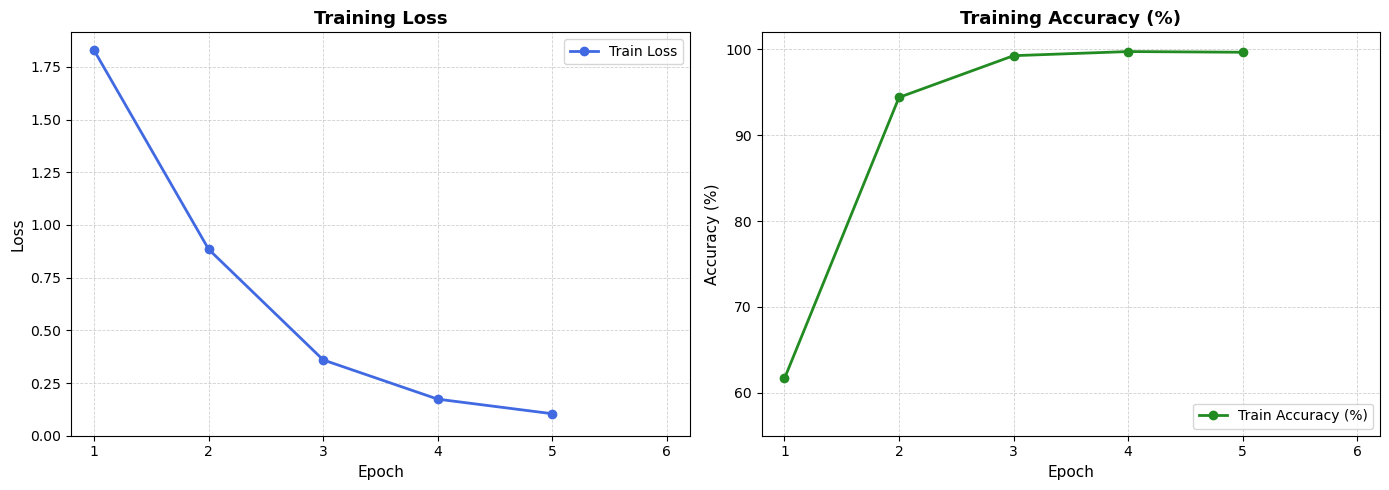

In [14]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Extracted Data
epochs = [1, 2, 3, 4, 5]
losses = [1.82798, 0.88423, 0.35965, 0.17353, 0.10438]
accuracies = [61.67, 94.42, 99.28, 99.76, 99.68]

# 2. Plotting
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curve (Linear Scale)
ax_loss.plot(
    epochs,
    losses,
    color="royalblue",
    lw=2,
    marker="o",
    markersize=6,
    label="Train Loss",
)
ax_loss.set_title("Training Loss", fontsize=13, fontweight="bold")
ax_loss.set_xlabel("Epoch", fontsize=11)
ax_loss.set_ylabel("Loss", fontsize=11)
ax_loss.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax_loss.set_xlim(0.8, 6.2)
ax_loss.set_ylim(bottom=0)
ax_loss.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
ax_loss.legend(loc="upper right")

# Accuracy Curve
ax_acc.plot(
    epochs,
    accuracies,
    color="forestgreen",
    lw=2,
    marker="o",
    markersize=6,
    label="Train Accuracy (%)",
)
ax_acc.set_title("Training Accuracy (%)", fontsize=13, fontweight="bold")
ax_acc.set_xlabel("Epoch", fontsize=11)
ax_acc.set_ylabel("Accuracy (%)", fontsize=11)
ax_acc.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax_acc.set_xlim(0.8, 6.2)
ax_acc.set_ylim(55, 102)
ax_acc.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)
ax_acc.legend(loc="lower right")

plt.tight_layout()
plt.show()


### Evaluate

In [73]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 5. Evaluate on intact Test Set
final_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = final_model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

# Compute metrics
raw_acc = accuracy_score(all_targets, all_preds)
bal_acc = balanced_accuracy_score(all_targets, all_preds)
macro_f1 = f1_score(all_targets, all_preds, average="macro")

print("=" * 55)
print(f"Standard Overall Accuracy: {raw_acc * 100:.2f}%")
print(f"Balanced Accuracy (Macro): {bal_acc * 100:.2f}%  <-- (Fair across all classes)")
print(f"Macro F1-Score:            {macro_f1 * 100:.2f}%")
print("=" * 55)

# Detailed per-class breakdown (using your idx_to_class mapping)
target_names = [idx_to_class[i] for i in range(len(idx_to_class))]
print("\nPer-Class Performance Breakdown:")
print(classification_report(all_targets, all_preds, target_names=target_names, digits=4))



Standard Overall Accuracy: 99.52%
Balanced Accuracy (Macro): 99.13%  <-- (Fair across all classes)
Macro F1-Score:            99.15%

Per-Class Performance Breakdown:
               precision    recall  f1-score   support

       dilmah     1.0000    1.0000    1.0000        63
           g7     1.0000    0.9899    0.9949        99
    jack-jill     1.0000    0.9231    0.9600        13
         karo     0.9655    1.0000    0.9825        28
 nestea_atiso     1.0000    1.0000    1.0000        40
 nestea_chanh     1.0000    1.0000    1.0000        41
nestea_hoaqua     1.0000    1.0000    1.0000        45
        orion     1.0000    1.0000    1.0000        48
         tipo     0.9565    1.0000    0.9778        22
          y40     1.0000    1.0000    1.0000        20

     accuracy                         0.9952       419
    macro avg     0.9922    0.9913    0.9915       419
 weighted avg     0.9954    0.9952    0.9952       419



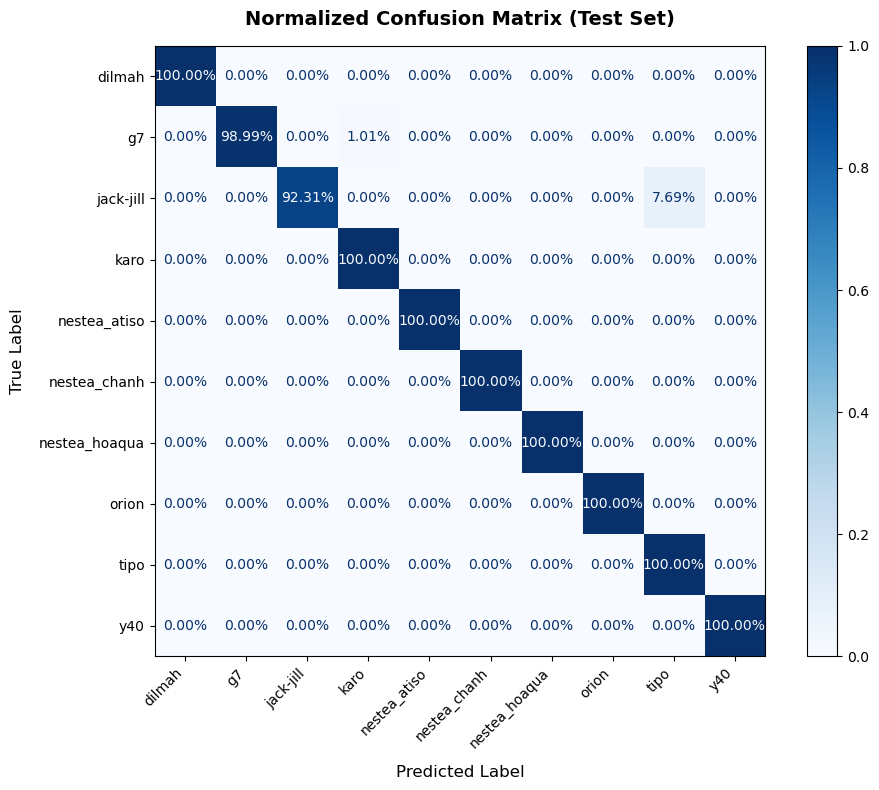

In [74]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = [idx_to_class[i] for i in range(len(idx_to_class))]

# 1. Compute Confusion Matrix (Normalized by true class rows to see % accuracy per class)
cm_normalized = confusion_matrix(all_targets, all_preds, normalize="true")

# 2. Plot
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format=".2%",   
    ax=ax,
    colorbar=True
)

plt.title("Normalized Confusion Matrix (Test Set)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Label", fontsize=12, labelpad=10)
plt.ylabel("True Label", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.grid(False)  # Turn off distracting grid lines on heatmaps
plt.tight_layout()
plt.show()


Total test errors: 2 / 419 images


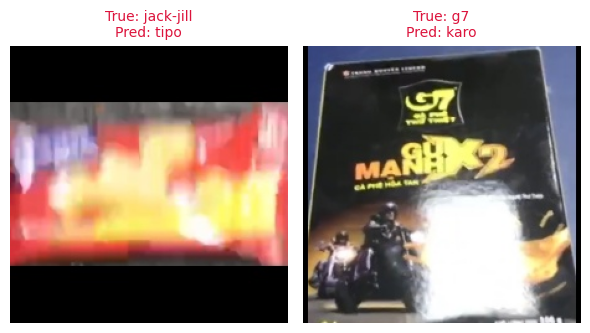

In [75]:
from PIL import Image

# Find test indices where prediction didn't match ground truth
test_indices = list(range(len(all_targets)))
errors = [i for i in test_indices if all_preds[i] != all_targets[i]]

print(f"Total test errors: {len(errors)} / {len(all_targets)} images")

# Plot up to 8 misclassified examples
num_show = min(8, len(errors))
if num_show > 0:
    fig, axes = plt.subplots(1, num_show, figsize=(3 * num_show, 3.5))
    if num_show == 1:
        axes = [axes]
        
    for ax, err_i in zip(axes, errors[:num_show]):
        # Map back to original image path
        global_test_idx = test_idx[err_i]
        img_path = image_paths[global_test_idx]
        
        true_name = idx_to_class[all_targets[err_i]]
        pred_name = idx_to_class[all_preds[err_i]]
        
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(f"True: {true_name}\nPred: {pred_name}", color="crimson", fontsize=10)
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()


==> Half white half other = Karo? 

-> Try increase saturation to boose distinctive color at other half of object

In [40]:
test_satboost_transform = transforms.Compose([
    transforms.ColorJitter(saturation=(1.1,1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
test_satboost_base_dataset = CustomDataset(image_paths, labels, transform=test_satboost_transform)
test_satboost_dataset = Subset(test_satboost_base_dataset, test_idx)
test_satboost_loader = DataLoader(
    test_satboost_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

===> Does not work

In [77]:

# 6. Save unfused & fused production models
save_dir = Path("./checkpoints")
save_dir.mkdir(parents=True, exist_ok=True)

torch.save(final_model.state_dict(), save_dir / "mobileone_s4_final_unfused.pth")
final_model_fused = reparameterize_model(final_model)
torch.save(final_model_fused.state_dict(), save_dir / "mobileone_s4_final_fused.pth")
print(f"Saved unfused -> {save_dir / 'mobileone_s4_final_unfused.pth'}")
print(f"Saved fused -> {save_dir / 'mobileone_s4_final_fused.pth'}")


Saved unfused -> checkpoints/mobileone_s4_final_unfused.pth
Saved fused -> checkpoints/mobileone_s4_final_fused.pth
